# Multiclass Classification with Keras

Multiclass classification is a type of supervised learning where the goal is to classify instances into one of three or more classes. In this notebook, we will use the Wine Dataset, which contains three classes of wine, to demonstrate how to build a multiclass classification model using Keras.

Dataset: Wine Dataset (3 classes)


## Requirements

1. Load the Wine dataset from scikit-learn.

2. Split the dataset into training and test sets.

3. Normalize the input features.

4. Convert class labels into one-hot encoding.

5. Build a neural network for multiclass classification using Keras.

6. Train the model with validation data.

7. Plot training and validation loss and accuracy.

8. Evaluate the model using Confusion Matrix and Classification Report.


In [ ]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

## Step 1: Load Dataset

Load the Wine dataset.
Extract input features X and class labels y.


In [ ]:
# Load Wine dataset
data = load_wine()
X = data.data
y = data.target

print("Input shape:", X.shape)
print("Number of classes:", len(np.unique(y)))

Input shape: (178, 13)
Number of classes: 3


## Step 2: Data Preprocessing

Split the dataset into training and test sets.
Apply feature scaling.
Convert labels to one-hot encoding.


In [ ]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature scaling using StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# One-hot encode labels
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

## Step 3: Build Neural Network Model

Build a neural network for multiclass classification.
Use Softmax activation in the output layer.


In [ ]:
# Sequential model
model = Sequential()

# Add hidden layers
model.add(Dense(16, activation='relu', input_shape=(X.shape[1],)))
model.add(Dense(16, activation='relu'))

# Add output layer with softmax activation
model.add(Dense(3, activation='softmax'))

# Compile the model with categorical_crossentropy
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Step 4: Train the Model

Train the model using training data.
Use validation_split to monitor model performance.


In [ ]:
# Train the model
history = model.fit(X_train, y_train, epochs=50,
                    batch_size=8, validation_split=0.2, verbose=1)

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.0885 - loss: 1.2308 - val_accuracy: 0.2069 - val_loss: 1.1258
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3009 - loss: 1.0913 - val_accuracy: 0.5862 - val_loss: 0.9915
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6106 - loss: 0.9785 - val_accuracy: 0.7586 - val_loss: 0.8801
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7345 - loss: 0.8855 - val_accuracy: 0.8621 - val_loss: 0.7845
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7876 - loss: 0.8014 - val_accuracy: 0.9310 - val_loss: 0.6920
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8230 - loss: 0.7217 - val_accuracy: 1.0000 - val_loss: 0.6078
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8850 - loss: 0.6464 - val_accuracy: 1.0000 - val_loss: 0.5293
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9204 - loss: 0.5739 - val_accuracy: 1.0000 - val_los

## Step 5: Visualization

Plot training and validation loss.
Plot training and validation accuracy.


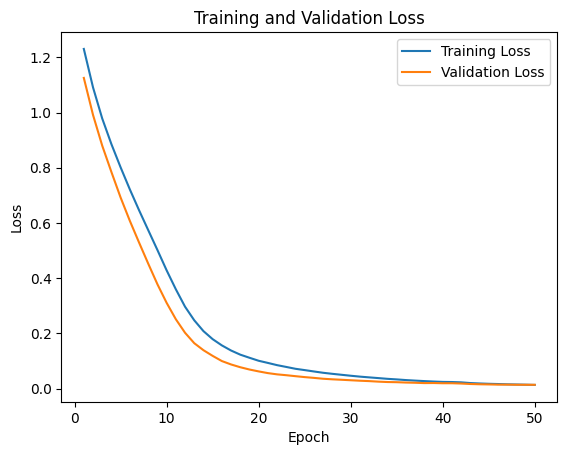

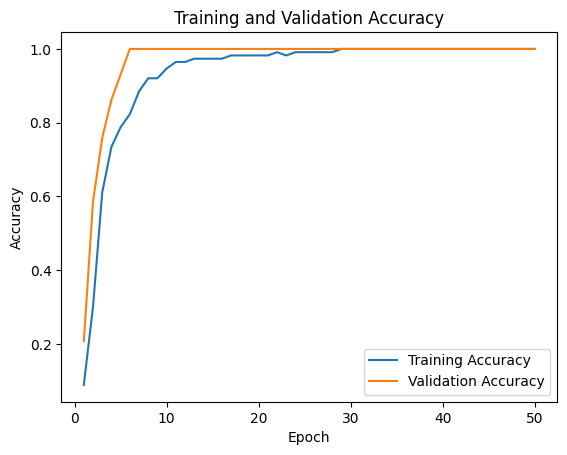

In [ ]:
# Plot loss and accuracy curves
loss = history.history['loss']
val_loss = history.history['val_loss']
accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

epochs = range(1, len(loss) + 1)

# Loss
plt.figure()
plt.plot(epochs, loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

# Accuracy
plt.figure()
plt.plot(epochs, accuracy, label='Training Accuracy')
plt.plot(epochs, val_accuracy, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

## Step 6: Model Evaluation

Evaluate the model on the test set.
Compute Confusion Matrix and Classification Report.


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


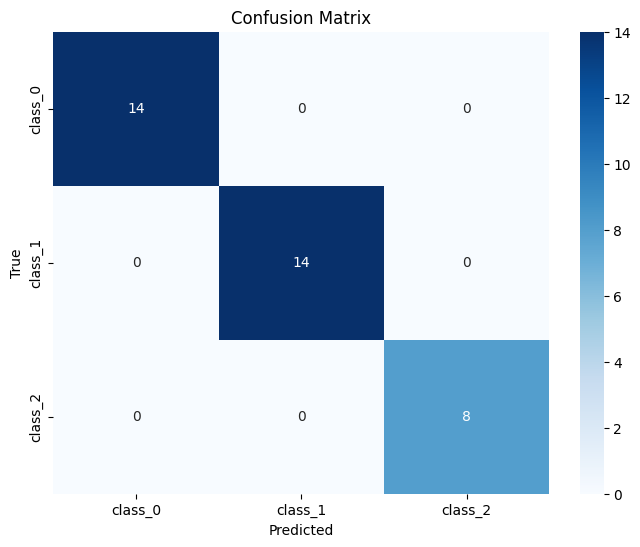

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



In [ ]:
# Predict class probabilities on test data
y_pred_prob = model.predict(X_test)

# Convert predictions to class labels
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

# Visualize Confusion Matrix using heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=data.target_names,
            yticklabels=data.target_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# TODO: Print classification report
print(classification_report(y_true, y_pred))

## Key Observations

1. Softmax is used for multi-class classification because it produce N probability values, corresponding N labels. Each `N_i` is the probability of the sample being label `i`.

2. One-Hot Encoding is used to convert the target labels into binary vectors. A recommended approach for Neural Networks as it prevents the model from assuming an artificial order or ranking between categorical target labels.

3. Increasing the number of hidden layers allows the model to learn more complex, intricate, non-linear relationships and abstract hierarchical features from data.